# Logistic Regression

This notebook trains and evaluates Logistic Regression using the shared
dataset split, preprocessing pipeline, cross-validation approach and metrics.
Logistic Regression is used as a simple baseline because it is interpretable
and works well with scaled numeric features and one-hot encoded categories.

In [17]:
from pathlib import Path
import sys

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data/processed/hotel_booking_features.csv").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

from scripts.model_evaluation_utils import (
    RANDOM_STATE,
    OUTPUT_DIR,
    load_feature_dataset,
    split_feature_dataset,
    class_distribution,
    build_pipeline,
    cross_validation_summary,
    fit_and_evaluate,
    confusion_matrix_frame,
)

FIGURE_DIR = OUTPUT_DIR / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load Shared Data Split

In [18]:
data = load_feature_dataset()
prepared = split_feature_dataset(data)

print(f"Training rows: {len(prepared.X_train):,}")
print(f"Test rows: {len(prepared.X_test):,}")

print("\nTraining class distribution")
display(class_distribution(prepared.y_train))

print("\nTest class distribution")
display(class_distribution(prepared.y_test))

Training rows: 95,364
Test rows: 23,841

Training class distribution


,class,count,percent
0,0,60008,62.9252
1,1,35356,37.0748



Test class distribution


,class,count,percent
0,0,15002,62.9252
1,1,8839,37.0748


## 2. Class Imbalance Review

In [19]:
training_distribution = class_distribution(prepared.y_train)
negative_count = int((prepared.y_train == 0).sum())
positive_count = int((prepared.y_train == 1).sum())
total_count = len(prepared.y_train)

class_weights = {
    0: total_count / (2 * negative_count),
    1: total_count / (2 * positive_count),
}

print("Balanced class weights used by LogisticRegression(class_weight='balanced'):")
print(class_weights)
display(training_distribution)

Balanced class weights used by LogisticRegression(class_weight='balanced'):
{0: 0.7945940541261165, 1: 1.3486254101142663}


,class,count,percent
0,0,60008,62.9252
1,1,35356,37.0748


## 3. Baseline Model

In [20]:
logistic_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    random_state=RANDOM_STATE,
)
logistic_pipeline = build_pipeline(logistic_model, prepared.X_train)
logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",1.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

## 4. Baseline Cross-Validation

In [21]:
logistic_cv = cross_validation_summary(
    "Logistic Regression",
    "Baseline",
    logistic_pipeline,
    prepared.X_train,
    prepared.y_train,
)
display(logistic_cv.round(4))

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Logistic Regression,Baseline,accuracy,0.8222,0.0008,0.8209,0.0017
1,Logistic Regression,Baseline,precision,0.8073,0.0012,0.8058,0.0042
2,Logistic Regression,Baseline,recall,0.6836,0.0014,0.6814,0.0084
3,Logistic Regression,Baseline,f1,0.7403,0.0012,0.7383,0.0039
4,Logistic Regression,Baseline,roc_auc,0.9048,0.0004,0.9039,0.0009
5,Logistic Regression,Baseline,pr_auc,0.8669,0.0004,0.8657,0.0010


**Interpretation:** Logistic Regression shows how well a simple linear model
can separate cancelled and non-cancelled bookings after the shared
preprocessing step. The cross-validation metrics are used to judge expected
generalization before looking at the final test set. A small gap between
training and validation scores indicates limited overfitting.

## 5. Baseline Final Test Evaluation

In [22]:
logistic_pipeline, logistic_test = fit_and_evaluate(
    "Logistic Regression",
    "Baseline",
    logistic_pipeline,
    prepared,
)

logistic_test_results = pd.DataFrame([logistic_test])
display(logistic_test_results.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Logistic Regression,Baseline,0.8243,0.8131,0.6832,0.7425,0.9051,0.8684,1.3121


**Test-set interpretation:** The final test metrics should be compared with
the cross-validation results. If the values are close, the model is behaving
consistently on unseen data. For this dataset, Logistic Regression is useful
as a stable and interpretable baseline, but its recall should be checked
carefully because low recall means more actual cancellations are missed.

## 6. Baseline Confusion Matrix

In [23]:
logistic_predictions = logistic_pipeline.predict(prepared.X_test)
logistic_confusion = confusion_matrix_frame(prepared.y_test, logistic_predictions)
display(logistic_confusion)

,Predicted 0,Predicted 1
Actual 0,13614,1388
Actual 1,2800,6039


## 7. Class-Weighted Logistic Regression

In [24]:
weighted_logistic_model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
weighted_logistic_pipeline = build_pipeline(weighted_logistic_model, prepared.X_train)
weighted_logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",1.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

## 8. Class-Weighted Cross-Validation

In [25]:
weighted_logistic_cv = cross_validation_summary(
    "Logistic Regression",
    "Class Weighted",
    weighted_logistic_pipeline,
    prepared.X_train,
    prepared.y_train,
)
display(weighted_logistic_cv.round(4))

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Logistic Regression,Class Weighted,accuracy,0.8176,0.0007,0.8162,0.0018
1,Logistic Regression,Class Weighted,precision,0.7332,0.0004,0.7314,0.0035
2,Logistic Regression,Class Weighted,recall,0.7986,0.0019,0.7972,0.0048
3,Logistic Regression,Class Weighted,f1,0.7645,0.0011,0.7628,0.0023
4,Logistic Regression,Class Weighted,roc_auc,0.9052,0.0004,0.9043,0.0009
5,Logistic Regression,Class Weighted,pr_auc,0.8650,0.0004,0.8639,0.0011


## 9. Class-Weighted Final Test Evaluation

In [26]:
weighted_logistic_pipeline, weighted_logistic_test = fit_and_evaluate(
    "Logistic Regression",
    "Class Weighted",
    weighted_logistic_pipeline,
    prepared,
)

weighted_logistic_test_results = pd.DataFrame([weighted_logistic_test])
display(weighted_logistic_test_results.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Logistic Regression,Class Weighted,0.8178,0.7369,0.7907,0.7629,0.9056,0.8668,1.3415


## 10. Class-Weighted Confusion Matrix

In [27]:
weighted_logistic_predictions = weighted_logistic_pipeline.predict(prepared.X_test)
weighted_logistic_confusion = confusion_matrix_frame(prepared.y_test, weighted_logistic_predictions)
display(weighted_logistic_confusion)

,Predicted 0,Predicted 1
Actual 0,12507,2495
Actual 1,1850,6989


## 11. Baseline vs Class-Weighted Comparison

In [28]:
logistic_test_results = pd.DataFrame([
    logistic_test,
    weighted_logistic_test,
])
logistic_cv_results = pd.concat([
    logistic_cv,
    weighted_logistic_cv,
], ignore_index=True)

display(logistic_test_results.round(4))
display(logistic_cv_results.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Logistic Regression,Baseline,0.8243,0.8131,0.6832,0.7425,0.9051,0.8684,1.3121
1,Logistic Regression,Class Weighted,0.8178,0.7369,0.7907,0.7629,0.9056,0.8668,1.3415


,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Logistic Regression,Baseline,accuracy,0.8222,0.0008,0.8209,0.0017
1,Logistic Regression,Baseline,precision,0.8073,0.0012,0.8058,0.0042
2,Logistic Regression,Baseline,recall,0.6836,0.0014,0.6814,0.0084
3,Logistic Regression,Baseline,f1,0.7403,0.0012,0.7383,0.0039
4,Logistic Regression,Baseline,roc_auc,0.9048,0.0004,0.9039,0.0009
5,Logistic Regression,Baseline,pr_auc,0.8669,0.0004,0.8657,0.0010
6,Logistic Regression,Class Weighted,accuracy,0.8176,0.0007,0.8162,0.0018
7,Logistic Regression,Class Weighted,precision,0.7332,0.0004,0.7314,0.0035
8,Logistic Regression,Class Weighted,recall,0.7986,0.0019,0.7972,0.0048
9,Logistic Regression,Class Weighted,f1,0.7645,0.0011,0.7628,0.0023


**Class-imbalance interpretation:** The class-weighted model gives the
cancellation class a larger penalty during training. This usually increases
recall for cancelled bookings, but it can reduce precision because more
bookings are predicted as cancellations. The final choice should depend on
whether missing cancellations is more costly than extra follow-up actions.

## 12. Coefficients and Odds Ratios

In [29]:
def coefficient_table(pipeline, version, top_n=15):
    feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
    coefficients = pipeline.named_steps["model"].coef_[0]
    frame = pd.DataFrame({
        "version": version,
        "feature": feature_names,
        "coefficient": coefficients,
        "odds_ratio": np.exp(coefficients),
        "absolute_coefficient": np.abs(coefficients),
    })
    return frame.sort_values("absolute_coefficient", ascending=False).head(top_n)

baseline_coefficients = coefficient_table(logistic_pipeline, "Baseline")
weighted_coefficients = coefficient_table(weighted_logistic_pipeline, "Class Weighted")

print("Top baseline coefficients")
display(baseline_coefficients.round(4))

print("Top class-weighted coefficients")
display(weighted_coefficients.round(4))

Top baseline coefficients


,version,feature,coefficient,odds_ratio,absolute_coefficient
12,Baseline,numeric__required_car_parking_spaces,-6.5642,0.0014,6.5642
17,Baseline,numeric__previous_cancellation_rate,5.9797,395.3372,5.9797
59,Baseline,categorical__deposit_type_Non Refund,2.5495,12.8007,2.5495
103,Baseline,high_cardinality__agent_240,2.2605,9.5882,2.2605
131,Baseline,high_cardinality__company_233,-2.1756,0.1135,2.1756
58,Baseline,categorical__deposit_type_No Deposit,-2.1005,0.1224,2.1005
121,Baseline,high_cardinality__agent_9,2.0867,8.0580,2.0867
143,Baseline,binary__is_repeated_guest,-1.8523,0.1569,1.8523
88,Baseline,high_cardinality__country_PRT,1.7915,5.9986,1.7915
138,Baseline,high_cardinality__company_51,-1.7116,0.1806,1.7116


Top class-weighted coefficients


,version,feature,coefficient,odds_ratio,absolute_coefficient
12,Class Weighted,numeric__required_car_parking_spaces,-6.9731,0.0009,6.9731
17,Class Weighted,numeric__previous_cancellation_rate,6.1190,454.4113,6.1190
59,Class Weighted,categorical__deposit_type_Non Refund,2.5438,12.7284,2.5438
103,Class Weighted,high_cardinality__agent_240,2.3402,10.3837,2.3402
121,Class Weighted,high_cardinality__agent_9,2.2329,9.3268,2.2329
131,Class Weighted,high_cardinality__company_233,-2.1445,0.1171,2.1445
58,Class Weighted,categorical__deposit_type_No Deposit,-2.0422,0.1297,2.0422
88,Class Weighted,high_cardinality__country_PRT,1.9708,7.1767,1.9708
143,Class Weighted,binary__is_repeated_guest,-1.8903,0.1510,1.8903
65,Class Weighted,high_cardinality__country_AGO,1.4986,4.4754,1.4986


**Coefficient interpretation:** Positive coefficients increase the log-odds
of cancellation, while negative coefficients reduce them. Odds ratios above
1 indicate higher cancellation odds; values below 1 indicate lower
cancellation odds. The class-weighted coefficients show how the model shifts
when cancelled bookings receive more importance during fitting.

## 13. ROC and Precision-Recall Curves

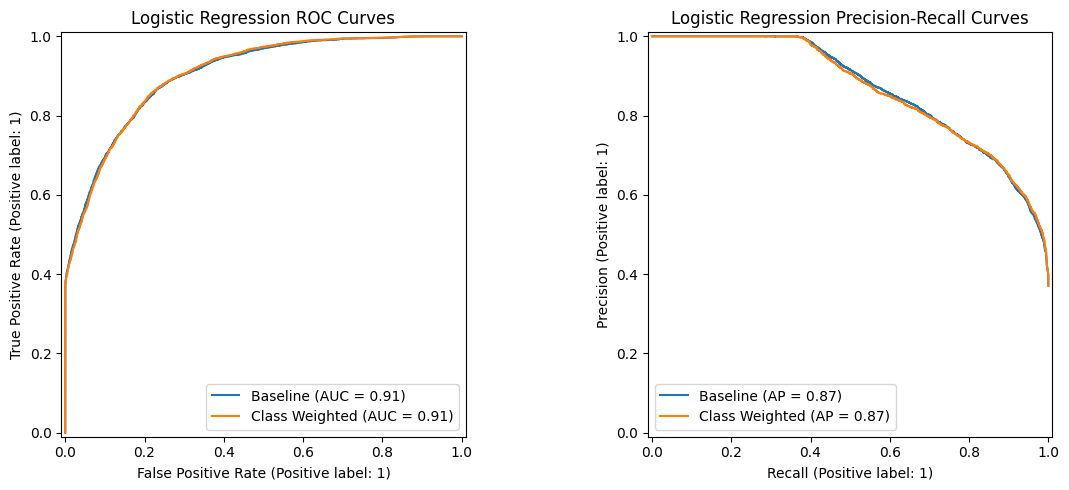

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_estimator(logistic_pipeline, prepared.X_test, prepared.y_test, ax=axes[0], name="Baseline")
RocCurveDisplay.from_estimator(weighted_logistic_pipeline, prepared.X_test, prepared.y_test, ax=axes[0], name="Class Weighted")
PrecisionRecallDisplay.from_estimator(logistic_pipeline, prepared.X_test, prepared.y_test, ax=axes[1], name="Baseline")
PrecisionRecallDisplay.from_estimator(weighted_logistic_pipeline, prepared.X_test, prepared.y_test, ax=axes[1], name="Class Weighted")
axes[0].set_title("Logistic Regression ROC Curves")
axes[1].set_title("Logistic Regression Precision-Recall Curves")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "logistic_regression_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 14. Interpretation Notes

Logistic Regression should remain in the final comparison as the interpretable
linear model. The baseline version shows normal performance at the natural
class distribution, while the class-weighted version directly addresses the
imbalance between cancelled and non-cancelled bookings. The coefficient
tables provide the explanation layer needed for the final report.